# OVM Assignment 1

Apple (AAPL) stock prices from **1 September 2025** to **31 August 2026**.


## Question 1a — Plot daily close prices


In [ ]:
import matplotlib.pyplot as plt
import yfinance as yf

# Download daily prices (end date is exclusive, so we use 1 Sep 2026)
close = yf.Ticker("AAPL").history(start="2025-09-01", end="2026-08-31")["Close"]

plt.figure(figsize=(10, 4))
plt.plot(close)
plt.title("AAPL — daily close price")
plt.xlabel("Date")
plt.ylabel("Close price (USD)")
plt.tight_layout()
plt.show()


Compute the daily return and daily logarithmic return and create plots to illustrate the patterns of both returns.


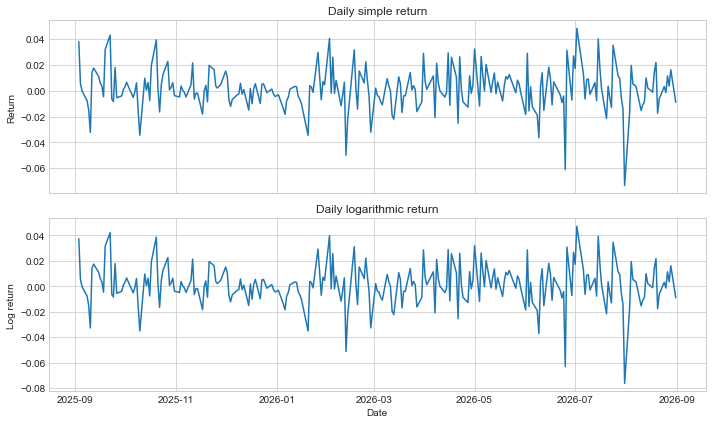

In [28]:
import numpy as np

# Simple daily return: (P_t - P_{t-1}) / P_{t-1}
daily_return = (close-close.shift(1))/close.shift(1)

# Log daily return: ln(P_t / P_{t-1})
log_return = np.log(close/close.shift(1))

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].plot(daily_return)
axes[0].set_title("Daily simple return")
axes[0].set_ylabel("Return")

axes[1].plot(log_return)
axes[1].set_title("Daily logarithmic return")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Log return")

plt.tight_layout()
plt.show()


Explain under what circumstances these two types of returns can be considered approxi-
mately identical.

When change in price has a mean approaching 0 and a low variance, the two returns can pe considered approximately identical in accordance with the fact that the logarithm function is used to reduce the variance.

### b)
Plot the histogram of daily logarithmic returns, compute the sample mean ˆμ and variance
ˆσ2, and produce the quantile-quantile plot, i.e., daily logarithmic returns vs. normal
distribution N(ˆμ, ˆσ2).

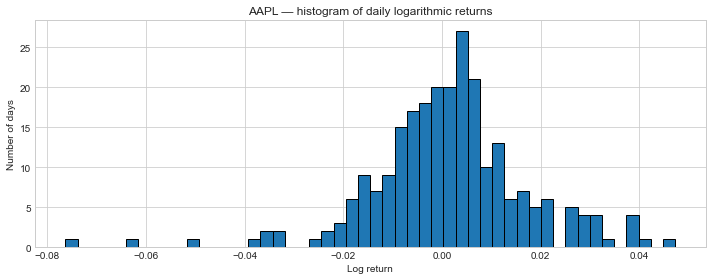

Sample mean: 0.0013010177017236206
Sample variance: 0.0002519120932142559


In [ ]:
log_returns_clean=log_return.dropna()
plt.figure(figsize=(10, 4))
plt.hist(log_returns_clean, bins=50, edgecolor="black")
plt.title("AAPL — histogram of daily logarithmic returns")
plt.xlabel("Log return")
plt.ylabel("Number of days")
plt.tight_layout()
plt.show()


mean_lr=log_returns_clean.mean()
var_lr=log_returns_clean.var()
sd_lr=np.sqrt(var_lr)

print("Sample mean:", mean_lr)
print("Sample variance:", var_lr)



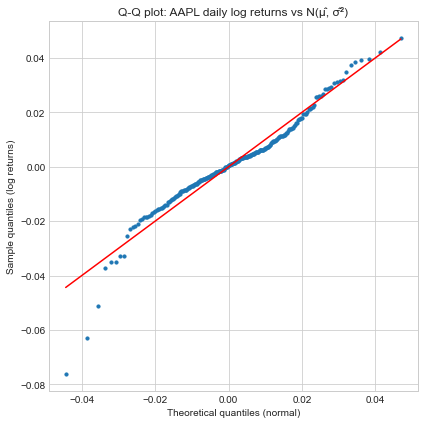

In [41]:
from scipy.stats import norm

sample_q=np.sort(log_returns_clean)
n=len(sample_q)
probabilities=(np.arange(1,n+1)-0.5)/n
theory_q=norm.ppf(probabilities,loc=mean_lr,scale=sd_lr)

plt.figure(figsize=(6, 6))
plt.scatter(theory_q,sample_q,s=10)
plt.plot(theory_q,theory_q,color="red")
plt.title("Q-Q plot: AAPL daily log returns vs N(μ̂, σ̂²)")
plt.xlabel("Theoretical quantiles (normal)")
plt.ylabel("Sample quantiles (log returns)")
plt.tight_layout()
plt.show()

Repeat the above process for the weekly close prices (4 years - 2022,2023,2024,2025), and
compare the Q Q plot patterns of weekly and daily returns.

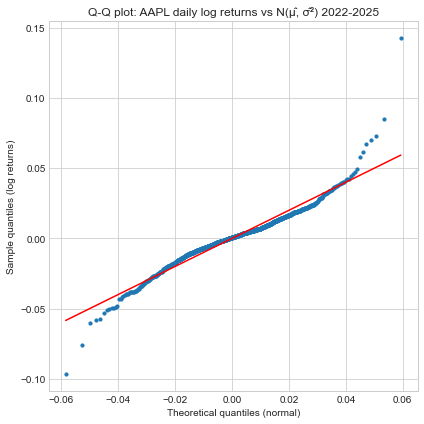

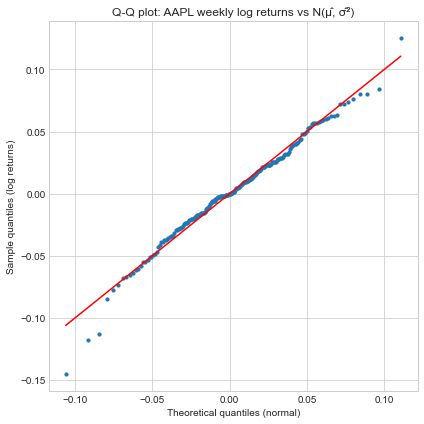

In [ ]:
close_day = yf.Ticker("AAPL").history(start="2022-01-01", end="2025-12-31")["Close"]
close_week = yf.Ticker("AAPL").history(start="2022-01-01", end="2025-12-31", interval="1wk")["Close"]

day_log_returns=np.log(close_day/close_day.shift(1))
day_log_returns=day_log_returns.dropna()
mean_d=day_log_returns.mean()
var_d=day_log_returns.var()
sd_d=np.sqrt(var_d)


week_log_returns=np.log(close_week/close_week.shift(1))
week_log_returns=week_log_returns.dropna()
mean_w=week_log_returns.mean()
var_w=week_log_returns.var()
sd_w=np.sqrt(var_w)

sample_q=np.sort(day_log_returns)
n=len(sample_q)
probabilities=(np.arange(1,n+1)-0.5)/n
theory_q=norm.ppf(probabilities,loc=mean_d,scale=sd_d)

plt.figure(figsize=(6, 6))
plt.scatter(theory_q,sample_q,s=10)
plt.plot(theory_q,theory_q,color="red")
plt.title("Q-Q plot: AAPL daily log returns vs N(μ̂, σ̂²) 2022-2025")
plt.xlabel("Theoretical quantiles (normal)")
plt.ylabel("Sample quantiles (log returns)")
plt.tight_layout()
plt.show()


sample_q=np.sort(week_log_returns)
n=len(sample_q)
probabilities=(np.arange(1,n+1)-0.5)/n
theory_q=norm.ppf(probabilities,loc=mean_w,scale=sd_w)

plt.figure(figsize=(6, 6))
plt.scatter(theory_q,sample_q,s=10)
plt.plot(theory_q,theory_q,color="red")
plt.title("Q-Q plot: AAPL weekly log returns vs N(μ̂, σ̂²)")
plt.xlabel("Theoretical quantiles (normal)")
plt.ylabel("Sample quantiles (log returns)")
plt.tight_layout()
plt.show()

